<div style="background: linear-gradient(135deg, #114F6A 0%, #1FA4B1 100%); padding: 28px; border-radius: 12px; color: #FFFFFF; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; box-shadow: 0 4px 12px rgba(17, 79, 106, 0.2);">
  <h1 style="margin: 0; font-size: 26px; letter-spacing: 1px; color: #FFFFFF;">PROYEK UTS PRAKTIKUM DEEP LEARNING</h1>
  <p style="margin: 6px 0 20px 0; font-size: 14px; color: #E0F7FA; opacity: 0.95;">Implementasi Sequence Deep Learning (RNN / LSTM) untuk Analisis Sentimen & Time-Series Forecasting</p>
  
  <div style="background-color: #FFFFFF; color: #1E293B; padding: 18px 22px; border-radius: 8px; border-left: 6px solid #114F6A;">
    <h3 style="margin: 0 0 12px 0; color: #114F6A; font-size: 16px; border-bottom: 2px solid #E2E8F0; padding-bottom: 6px;">DATA DIRI & KONFIGURASI PROYEK</h3>
    <table style="width: 100%; border-collapse: collapse; font-size: 14px; color: #1E293B;">
      <tr>
        <td style="padding: 6px 0; width: 220px; font-weight: bold; color: #114F6A;">Nama Lengkap</td>
        <td style="padding: 6px 0;">: Muhammad Hanif Nuruddin Jabbar</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">NIM</td>
        <td style="padding: 6px 0;">: 202432042</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kelas</td>
        <td style="padding: 6px 0;">: B</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kategori Tugas</td>
        <td style="padding: 6px 0;">: Forecasting Time-Series</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Algoritma yang Dipilih</td>
        <td style="padding: 6px 0;">: <span style="background-color: #1FA4B1; color: #FFFFFF; padding: 2px 10px; border-radius: 4px; font-weight: bold;">LSTM</span></td>
      </tr>
    </table>
  </div>
</div>

#

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 12px;">
  <div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 16px; border-bottom: 4px solid #1FA4B1;">
    BAB 1 - LATAR BELAKANG MASALAH
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 20px; line-height: 1.7; font-size: 14px;">
    <p style="margin-top: 0;">
      <b>1. Deskripsi Permasalahan:</b><br>
      Listrik tidak dapat disimpan dalam skala besar secara ekonomis, sehingga produksi harus mengikuti konsumsi dari jam ke jam. Perkiraan beban yang meleset dapat menyebabkan pemborosan bahan bakar atau risiko kekurangan pasokan. Konsumsi listrik memiliki pola harian, mingguan, dan musiman serta dipengaruhi tren jangka panjang, sehingga cocok dianalisis sebagai deret waktu. Hubungan antarwaktu yang bersifat non-linear seperti ini dapat ditangkap dengan baik oleh pendekatan Deep Learning berbasis sekuens. Kasus yang dipilih adalah peramalan konsumsi listrik di Rumania.
    </p>
    <p style="margin-bottom: 0;">
      <b>2. Tujuan Pemodelan & Alasan Pemilihan Algoritma:</b><br>
      Tujuan pemodelan adalah memprediksi konsumsi listrik rata-rata harian satu hari ke depan berdasarkan data 30 hari sebelumnya, lalu mengevaluasi akurasinya dengan RMSE, MAE, MAPE, dan R&sup2; pada data uji. LSTM dipilih karena memiliki cell state dan tiga gate (forget, input, output) yang mengatasi masalah vanishing gradient pada RNN standar. Dengan demikian LSTM mampu mengingat pola jangka panjang, seperti siklus mingguan dan musiman, pada jendela masukan 30 langkah waktu.
    </p>
  </div>
</div>

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: sans-serif; margin-top: 10px;">
<div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 15px; border-bottom: 4px solid #1FA4B1;">INFORMASI &amp; KARAKTERISTIK DATASET KAGGLE</div>
<div style="background-color: #F8FAFC; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
<div style="background-color: #E0F7FA; border-left: 5px solid #1FA4B1; padding: 12px 16px; border-radius: 4px; margin-bottom: 14px;">
<b style="color: #114F6A;">Nama Dataset:</b> Hourly Electricity Consumption and Production (stefancomanita)<br>
<b style="color: #114F6A;">Link Dataset Kaggle:</b> <a href="https://www.kaggle.com/datasets/stefancomanita/hourly-electricity-consumption-and-production" target="_blank" style="color: #114F6A; font-weight: bold; text-decoration: underline;">https://www.kaggle.com/datasets/stefancomanita/hourly-electricity-consumption-and-production</a>
</div>
<div style="margin-bottom: 12px;">
<b style="color: #114F6A;">Penjelasan Umum Dataset:</b><br>
Dataset berisi data per jam konsumsi dan produksi listrik menurut jenis sumber energi di Rumania. Jumlah data adalah <b>62,810 baris</b> dan <b>10 kolom</b> dengan rentang waktu <b>1 Januari 2019 00:00 sampai 14 Maret 2026 23:00</b>. Tidak ada missing value, tetapi terdapat 11 timestamp duplikat dan sekitar 321 jam yang hilang dari urutan per jam. Keduanya ditangani pada tahap pra-pemrosesan.
</div>
<div>
<b style="color: #114F6A;">Atribut Dataset:</b>
<table style="width: 100%; border-collapse: collapse; font-size: 13px; margin-top: 6px;">
<tr style="background-color: #114F6A; color: #FFFFFF;"><th style="padding: 6px; text-align: left;">Kolom</th><th style="padding: 6px; text-align: left;">Keterangan</th></tr>
<tr><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;">DateTime</td><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;">Penanda waktu per jam</td></tr>
<tr><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;"><b>Consumption</b></td><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;"><b>Konsumsi listrik (variabel target peramalan)</b></td></tr>
<tr><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;">Production</td><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;">Total produksi listrik</td></tr>
<tr><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;">Nuclear, Wind, Hydroelectric, Oil and Gas, Coal, Solar, Biomass</td><td style="padding: 5px; border-bottom: 1px solid #E2E8F0;">Produksi listrik menurut jenis sumber energi</td></tr>
</table>
<p style="margin: 8px 0 0 0;">Dataset ini tidak memiliki label kelas karena tugasnya adalah regresi deret waktu. Model yang dibangun bersifat univariat dengan target <code>Consumption</code>.</p>
</div>
</div>
</div>

#

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">1. IMPORT LIBRARY</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat pustaka komputasi numerik, manipulasi data, visualisasi grafik, dan kerangka kerja PyTorch.</p>
</div>

In [ ]:
#202432042_MuhammadHanifNuruddinJabbar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">2. PRA-PEMROSESAN DATA (PREPROCESSING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat dataset, membersihkan data, melakukan normalisasi / tokenisasi sekuens, serta membagi data latih dan data uji.</p>
</div>

In [ ]:
#202432042_MuhammadHanifNuruddinJabbar
# 1. Muat dataset dari repositori GitHub
URL = "https://raw.githubusercontent.com/hanifnrddin/UTS-DeepLearning-202432042/refs/heads/main/electricityConsumptionAndProductioction.csv"
df = pd.read_csv(URL, parse_dates=['DateTime'])
print("Ukuran dataset mentah :", df.shape)
print("Rentang waktu         :", df['DateTime'].min(), "s/d", df['DateTime'].max())
print("Total missing value   :", df.isna().sum().sum())
print("Timestamp duplikat    :", df['DateTime'].duplicated().sum())
display(df.head())

# 2. Pembersihan data & pra-pemrosesan (Forecasting)
df = df.groupby('DateTime')[['Consumption']].mean()
hourly = df.resample('h').mean()
print("Jam yang hilang       :", hourly['Consumption'].isna().sum())
hourly = hourly.interpolate(method='time')
daily = hourly['Consumption'].resample('D').mean()
print("Jumlah data harian    :", len(daily))

# 3. Pembagian data latih/uji secara kronologis (80:20) dan normalisasi Min-Max
WINDOW = 30
train_size = int(len(daily) * 0.8)
vmin = daily.iloc[:train_size].min()
vmax = daily.iloc[:train_size].max()
scaled = ((daily - vmin) / (vmax - vmin)).values.astype(np.float32)

# 4. Pembentukan sliding window
def create_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i + window])
        y.append(data[i + window])
    return np.array(X), np.array(y)

X_all, y_all = create_sequences(scaled, WINDOW)
n_train = train_size - WINDOW
X_train, y_train = X_all[:n_train], y_all[:n_train]
X_test, y_test = X_all[n_train:], y_all[n_train:]
test_dates = daily.index[train_size:]

# 5. Konversi ke PyTorch Tensor dan DataLoader
X_train = torch.tensor(X_train).unsqueeze(-1)
y_train = torch.tensor(y_train).unsqueeze(-1)
X_test = torch.tensor(X_test).unsqueeze(-1)
y_test = torch.tensor(y_test).unsqueeze(-1)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)

print("\nX_train:", tuple(X_train.shape), "| y_train:", tuple(y_train.shape))
print("X_test :", tuple(X_test.shape), "| y_test :", tuple(y_test.shape))

Ukuran dataset mentah : (62810, 10)
Rentang waktu         : 2019-01-01 00:00:00 s/d 2026-03-14 23:00:00
Total missing value   : 0
Timestamp duplikat    : 11


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,2019-01-01 00:00:00,6352,6527,1395,79,1383,1896,1744,0,30
1,2019-01-01 01:00:00,6116,5701,1393,96,1112,1429,1641,0,30
2,2019-01-01 02:00:00,5873,5676,1393,142,1030,1465,1616,0,30
3,2019-01-01 03:00:00,5682,5603,1397,191,972,1455,1558,0,30
4,2019-01-01 04:00:00,5557,5454,1393,159,960,1454,1458,0,30


Jam yang hilang       : 321
Jumlah data harian    : 2630

X_train: (2074, 30, 1) | y_train: (2074, 1)
X_test : (526, 30, 1) | y_test : (526, 1)


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">3. PEMODELAN ARSITEKTUR JARINGAN (RNN / LSTM)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Mendefinisikan kelas arsitektur model sekuensial menggunakan modul torch.nn sesuai algoritma yang dipilih.</p>
</div>

In [ ]:
#202432042_MuhammadHanifNuruddinJabbar
class SequenceModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_size=1, dropout=0.2):
        super(SequenceModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        return self.fc(out)

# Ringkasan arsitektur
print(SequenceModel())
print("Jumlah parameter:", sum(p.numel() for p in SequenceModel().parameters()))

SequenceModel(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Jumlah parameter: 50497


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">4. INISIASI HYPERPARAMETER & PROSES PELATIHAN (TRAINING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menentukan konfigurasi hyperparameter (learning rate, epochs, loss function, optimizer) dan menjalankan siklus pelatihan model.</p>
</div>

In [ ]:
#202432042_MuhammadHanifNuruddinJabbar
# 1. Inisiasi hyperparameter
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
epochs = 50
learning_rate = 0.001
hidden_size = 64
num_layers = 2

# 2. Inisiasi model, fungsi Loss, dan Optimizer
model = SequenceModel(hidden_size=hidden_size, num_layers=num_layers).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 3. Simpan riwayat nilai loss
train_losses = []
test_losses = []

# 4. Training loop
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
    train_loss = running_loss / len(train_loader.dataset)

    model.eval()
    with torch.no_grad():
        test_loss = criterion(model(X_test.to(device)), y_test.to(device)).item()

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1:>2}/{epochs}] | Train Loss: {train_loss:.6f} | Test Loss: {test_loss:.6f}")

Epoch [ 1/50] | Train Loss: 0.072148 | Test Loss: 0.024359
Epoch [ 5/50] | Train Loss: 0.012186 | Test Loss: 0.013928
Epoch [10/50] | Train Loss: 0.012139 | Test Loss: 0.013524
Epoch [15/50] | Train Loss: 0.011376 | Test Loss: 0.013119
Epoch [20/50] | Train Loss: 0.010670 | Test Loss: 0.012523
Epoch [25/50] | Train Loss: 0.005924 | Test Loss: 0.007608
Epoch [30/50] | Train Loss: 0.003416 | Test Loss: 0.005861
Epoch [35/50] | Train Loss: 0.003135 | Test Loss: 0.006142
Epoch [40/50] | Train Loss: 0.002742 | Test Loss: 0.005090
Epoch [45/50] | Train Loss: 0.002624 | Test Loss: 0.005148
Epoch [50/50] | Train Loss: 0.002571 | Test Loss: 0.005100


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">5. VISUALISASI LOSS TRAINING & PERBANDINGAN PREDIKSI VS AKTUAL</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menampilkan grafik konvergensi nilai Loss terhadap Epoch dan grafik evaluasi perbandingan hasil prediksi model terhadap data aktual.</p>
</div>

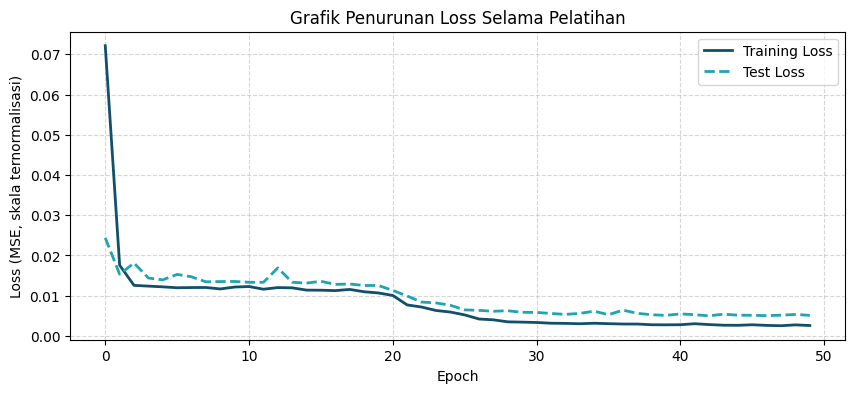

RMSE : 348.31
MAE  : 243.44
MAPE : 3.94 %
R2   : 0.8063


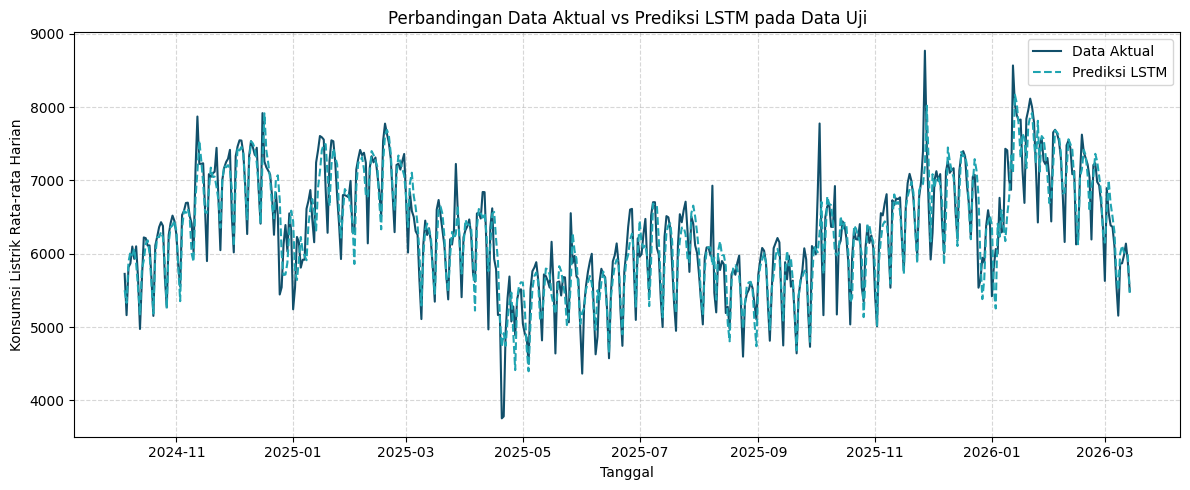

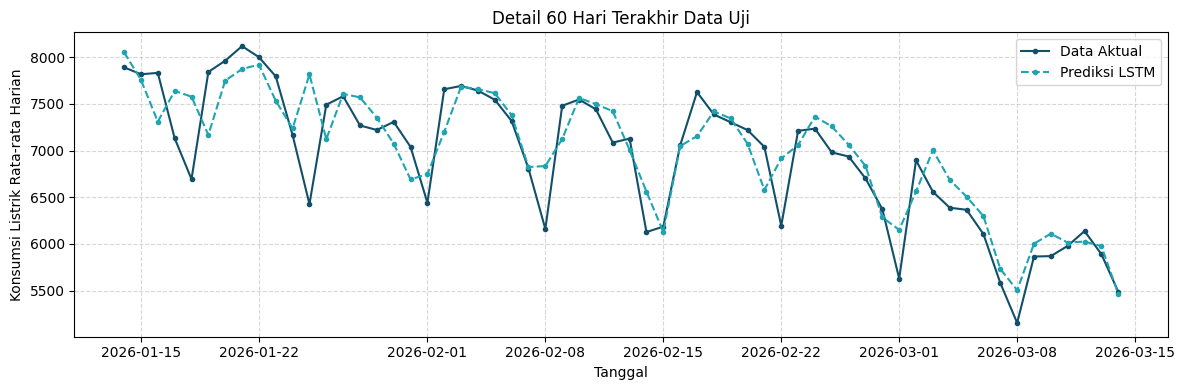

In [ ]:
#202432042_MuhammadHanifNuruddinJabbar
# 1. Plot Grafik Penurunan Loss Training terhadap Epoch
plt.figure(figsize=(10, 4))
plt.plot(train_losses, color='#114F6A', linewidth=2, label='Training Loss')
plt.plot(test_losses, color='#1FA4B1', linewidth=2, linestyle='--', label='Test Loss')
plt.title('Grafik Penurunan Loss Selama Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE, skala ternormalisasi)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 2. Prediksi pada data uji dan pengembalian ke skala asli
model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test.to(device)).cpu().numpy().flatten()
y_true = y_test.numpy().flatten() * (vmax - vmin) + vmin
y_pred = y_pred_scaled * (vmax - vmin) + vmin

# 3. Metrik evaluasi
rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
mae = np.mean(np.abs(y_true - y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MAPE : {mape:.2f} %")
print(f"R2   : {r2:.4f}")

# 4. Plot Grafik Perbandingan Data Aktual vs Hasil Prediksi Model
plt.figure(figsize=(12, 5))
plt.plot(test_dates, y_true, color='#114F6A', linewidth=1.5, label='Data Aktual')
plt.plot(test_dates, y_pred, color='#1FA4B1', linewidth=1.5, linestyle='--', label='Prediksi LSTM')
plt.title('Perbandingan Data Aktual vs Prediksi LSTM pada Data Uji')
plt.xlabel('Tanggal')
plt.ylabel('Konsumsi Listrik Rata-rata Harian')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 5. Tampilan detail 60 hari terakhir data uji
plt.figure(figsize=(12, 4))
plt.plot(test_dates[-60:], y_true[-60:], color='#114F6A', marker='o', markersize=3, label='Data Aktual')
plt.plot(test_dates[-60:], y_pred[-60:], color='#1FA4B1', marker='o', markersize=3, linestyle='--', label='Prediksi LSTM')
plt.title('Detail 60 Hari Terakhir Data Uji')
plt.xlabel('Tanggal')
plt.ylabel('Konsumsi Listrik Rata-rata Harian')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <div style="background-color: #1FA4B1; color: #FFFFFF; padding: 10px 20px; font-weight: bold; font-size: 15px;">
    RINGKASAN ANALISIS PERFORMA MODEL
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
    <p style="margin: 0;">
      <b>Kesimpulan Hasil Visualisasi:</b><br>
      Kurva loss menurun cukup cepat pada epoch awal (train loss 0,0721 pada epoch 1 menjadi sekitar 0,012 pada epoch 5), sempat mendatar sampai sekitar epoch 20, lalu turun tajam hingga epoch 30 dan stabil di sekitar 0,0026 (train) dan 0,0051 (test) pada epoch 50. Test loss mengikuti train loss tanpa kenaikan di akhir pelatihan, sehingga tidak terlihat overfitting yang berarti. Selisih kecil antara keduanya wajar karena data uji berisi pola yang tidak muncul persis sama pada data latih.<br><br>Pada data uji (526 hari, Oktober 2024 sampai Maret 2026), model mencapai <b>RMSE 348,31</b>, <b>MAE 243,44</b>, <b>MAPE 3,94%</b>, dan <b>R&sup2; 0,8063</b>. Kurva prediksi mengikuti pola aktual dengan baik, termasuk siklus mingguan dan perubahan musiman antara periode konsumsi tinggi (musim dingin) dan rendah (musim semi hingga musim panas). Kelemahan model terlihat pada lonjakan dan penurunan ekstrem: puncak tertinggi pada akhir November 2025 dan titik terendah pada April 2025 diprediksi kurang tajam. Hal ini umum pada model univariat yang hanya memakai riwayat konsumsi tanpa informasi eksternal seperti cuaca atau hari libur.
    </p>
  </div>
</div>